In [1]:
!pip install mne

In [2]:
import mne
import numpy as np
import matplotlib.pyplot as plt
import os

In [3]:
sample_data_path = mne.datasets.sample.data_path()
# raw = mne.io.read_raw_edf(sample_data_file, preload=True)
raw_file = os.path.join(sample_data_path, 'MEG', 'sample', 'sample_audvis_raw.fif')

Using default location ~/mne_data for sample...
Creating /root/mne_data
Fetching 1 file for the sample dataset ...


  0%|                                              | 0.00/1.65G [00:00<?, ?B/s]

Untarring contents of '/root/mne_data/MNE-sample-data-processed.tar.gz' to '/root/mne_data'


Attempting to create new mne-python configuration file:
/root/.mne/mne-python.json
Could not read the /root/.mne/mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
Download complete in 02m35s (1576.2 MB)


In [4]:
raw = mne.io.read_raw_fif(raw_file, preload=True)

Opening raw data file /root/mne_data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Reading 0 ... 166799  =      0.000 ...   277.714 secs...


Using matplotlib as 2D backend.


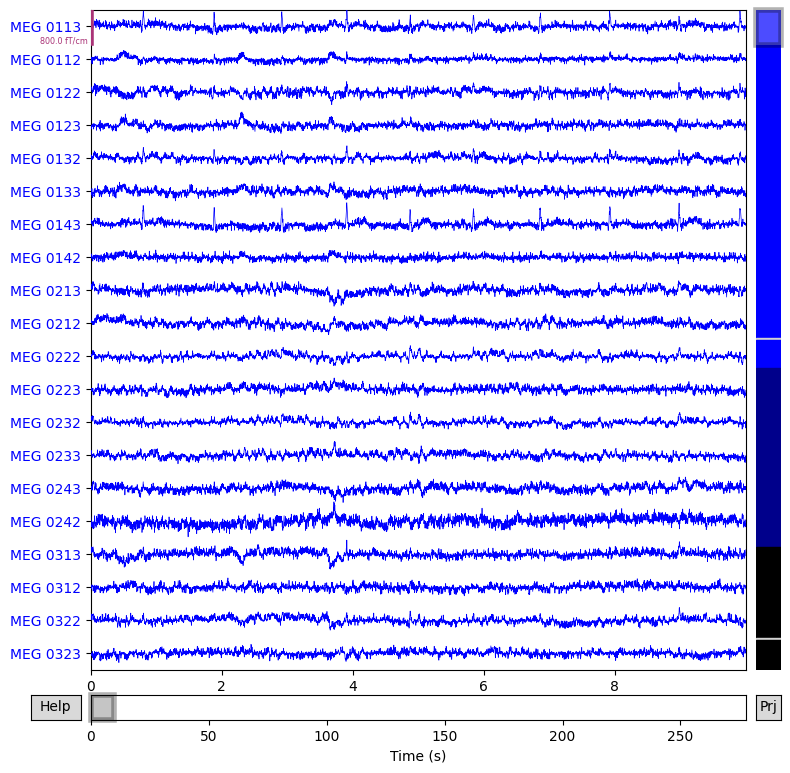

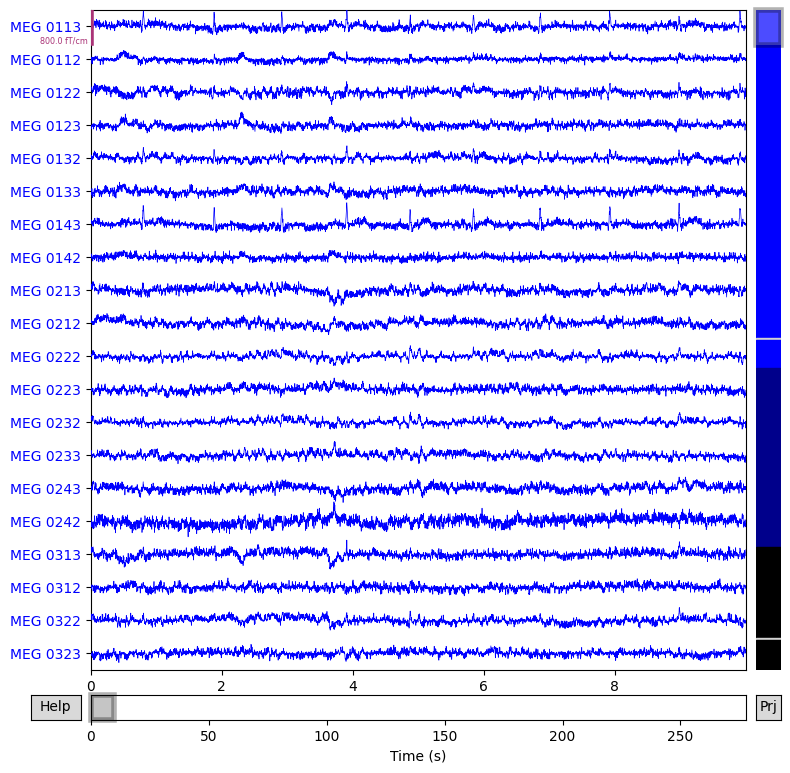

In [5]:
raw.plot()

In [6]:
raw.info

<Info | 21 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: acquisition (megacq) VectorView system at NMR-MGH
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 lowpass: 172.2 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 1
 proj_name: test
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
>

In [7]:
len(raw.ch_names)

376

In [8]:
raw.info['sfreq']

600.614990234375

In [9]:
raw.info

<Info | 21 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: acquisition (megacq) VectorView system at NMR-MGH
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 lowpass: 172.2 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 1
 proj_name: test
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
>

In [10]:
raw.times[-1]

np.float64(277.7136813300495)

In [11]:
raw_eeg = raw.copy().pick('eeg')

In [12]:
raw_eeg

<Raw | sample_audvis_raw.fif, 60 x 166800 (277.7 s), ~79.3 MiB, data loaded>

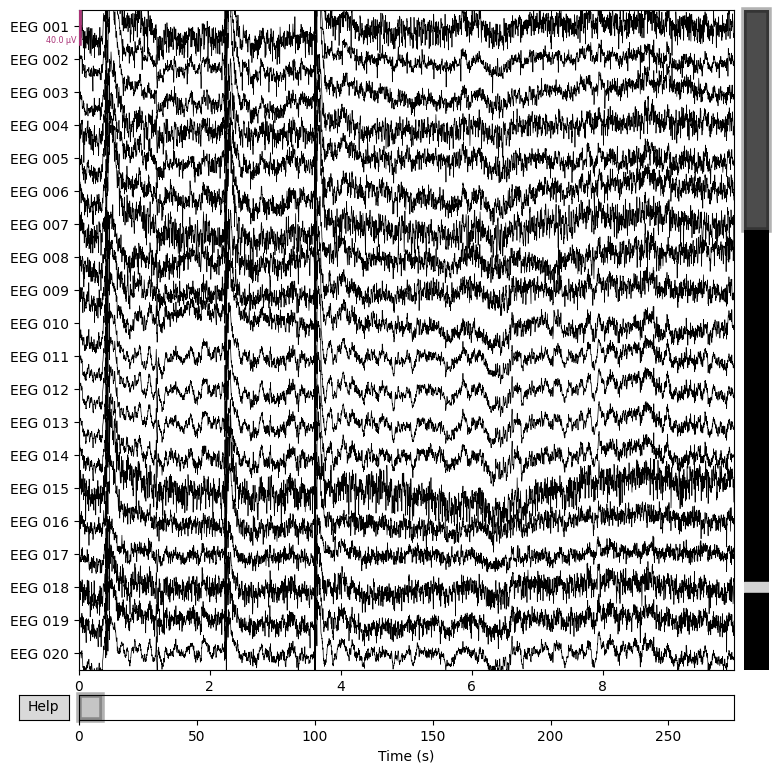

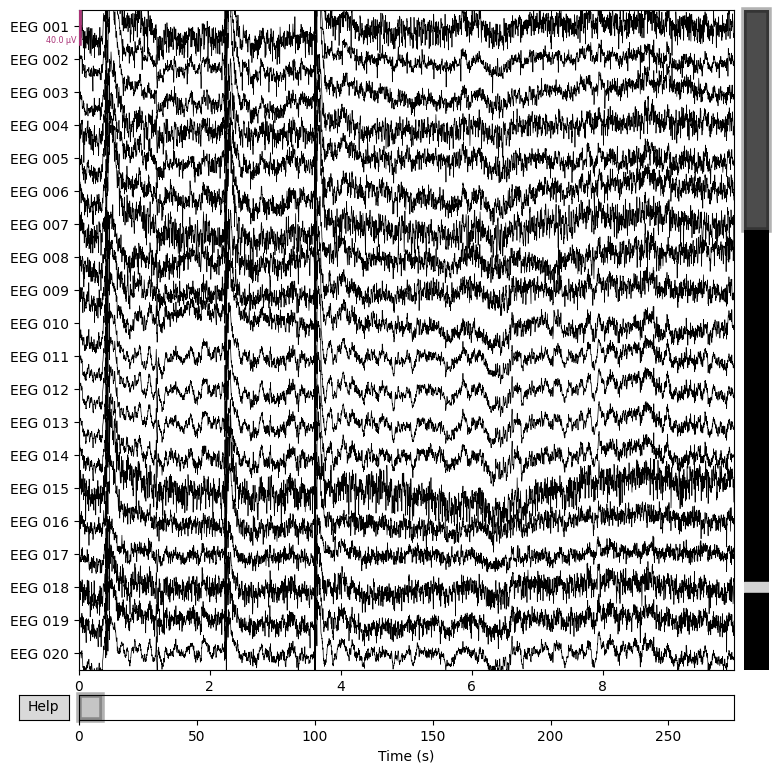

In [13]:
raw_eeg.plot()

In [14]:
raw.duration

np.float64(277.7153462901591)

In [15]:
len(raw)

166800

In [16]:
raw_filtered = raw_eeg.copy().filter(l_freq=0.5, h_freq=40)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 3965 samples (6.602 s)



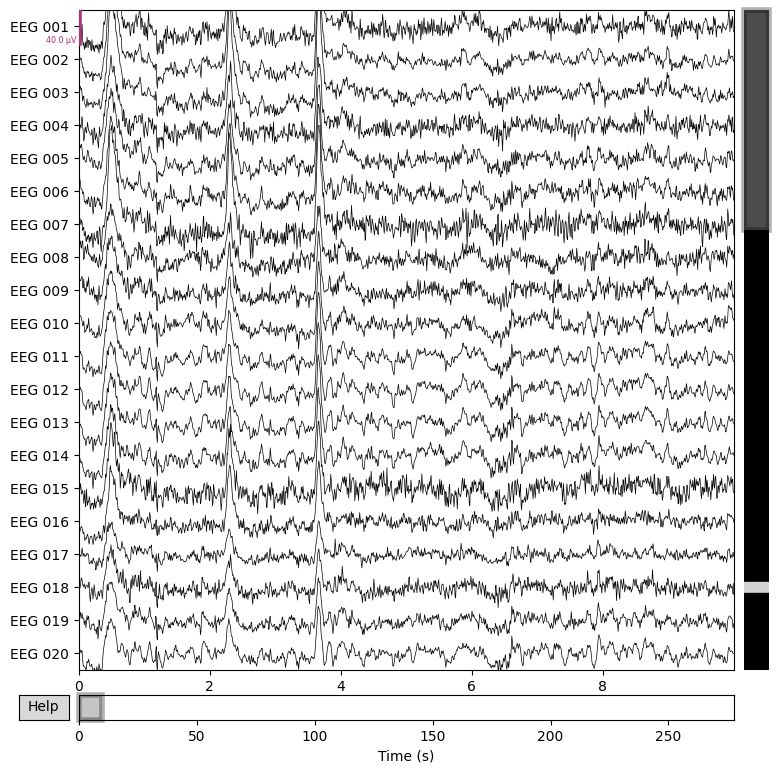

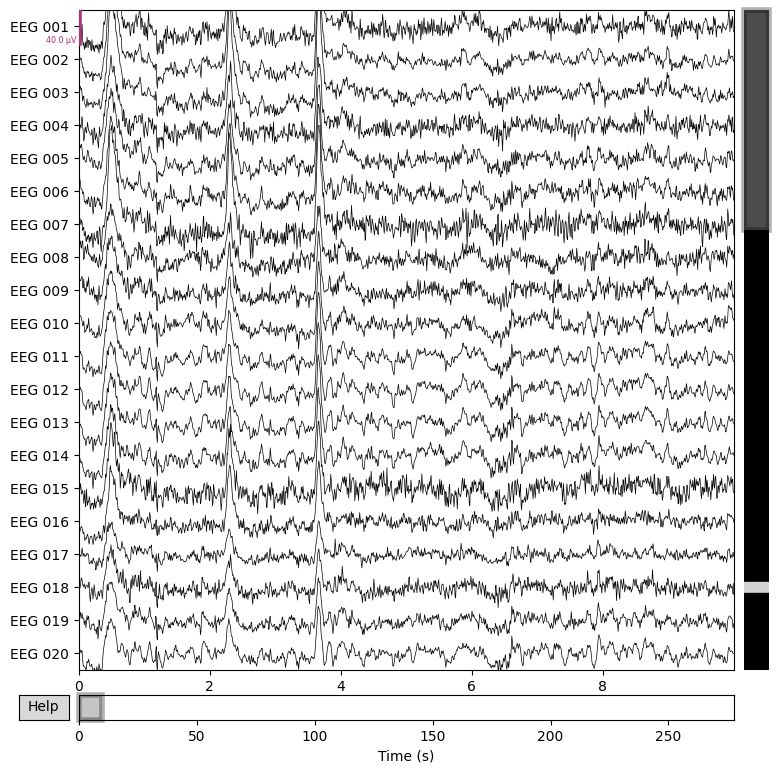

In [17]:
raw_filtered.plot()

Effective window size : 3.410 (s)
Plotting power spectral density (dB=True).


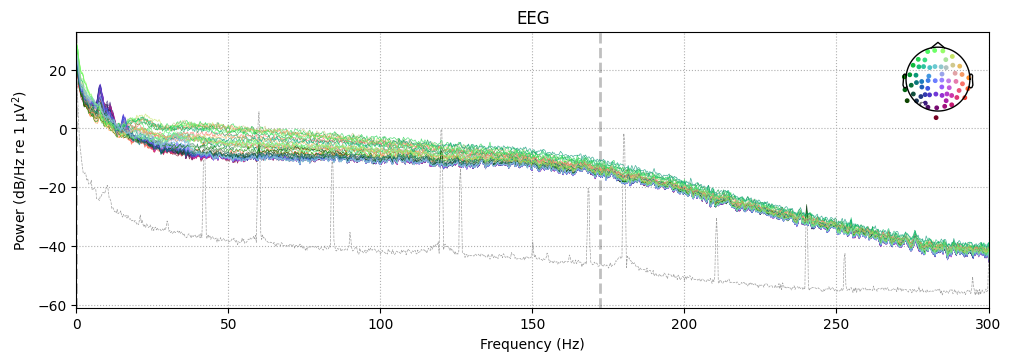

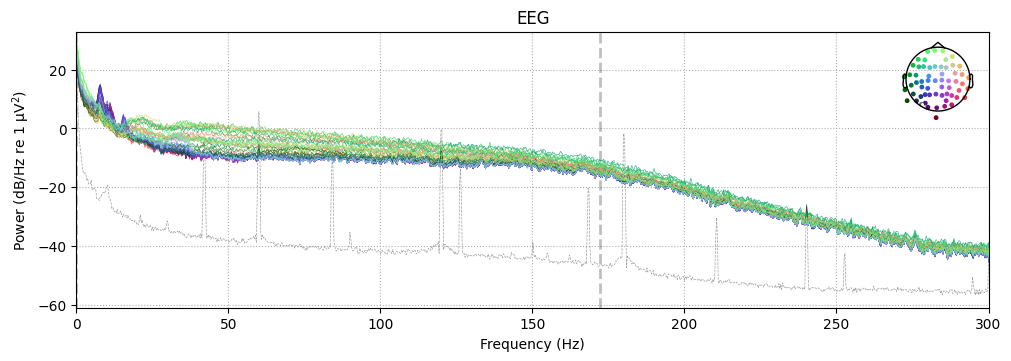

In [18]:
raw_eeg.compute_psd().plot()

Effective window size : 3.410 (s)
Plotting power spectral density (dB=True).


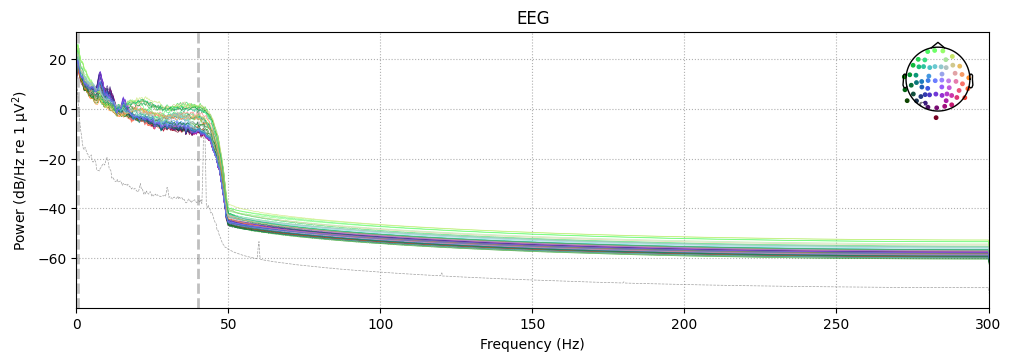

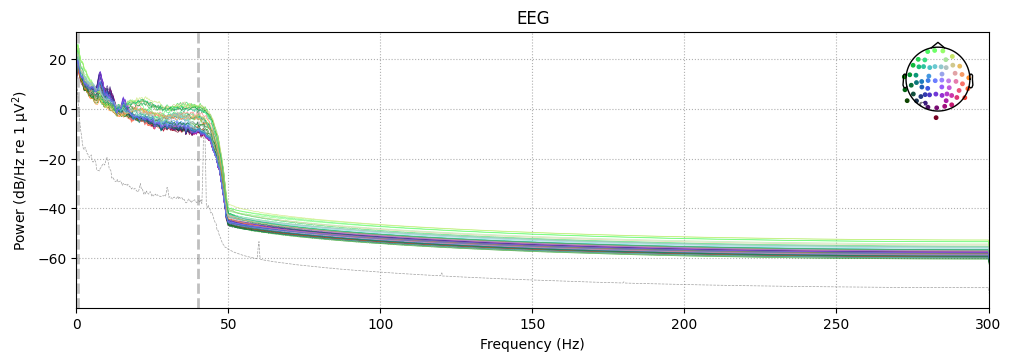

In [19]:
raw_filtered.compute_psd().plot()

In [20]:
raw.info

<Info | 21 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: acquisition (megacq) VectorView system at NMR-MGH
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 lowpass: 172.2 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 1
 proj_name: test
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
>

In [21]:
raw.copy().pick('eog')

<Raw | sample_audvis_raw.fif, 1 x 166800 (277.7 s), ~4.2 MiB, data loaded>

In [22]:
mne.preprocessing.ICA

mne.preprocessing.ica.ICA

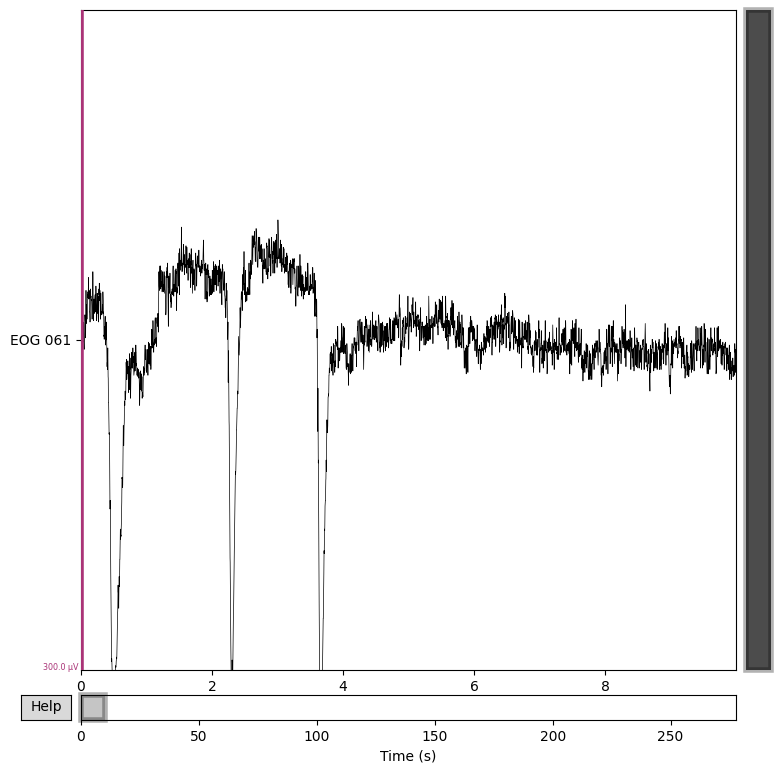

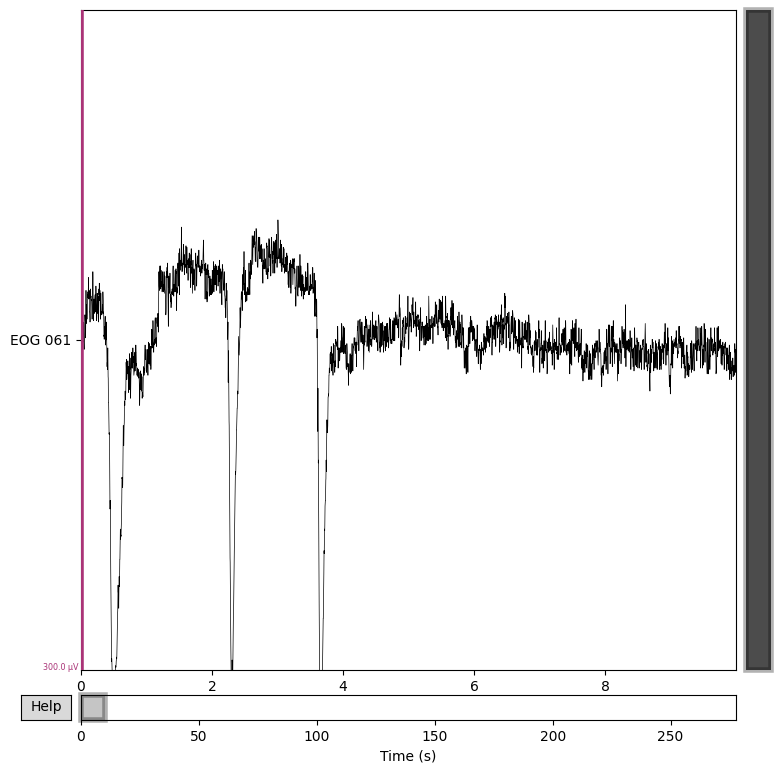

In [23]:
raw.copy().pick('eog').plot()

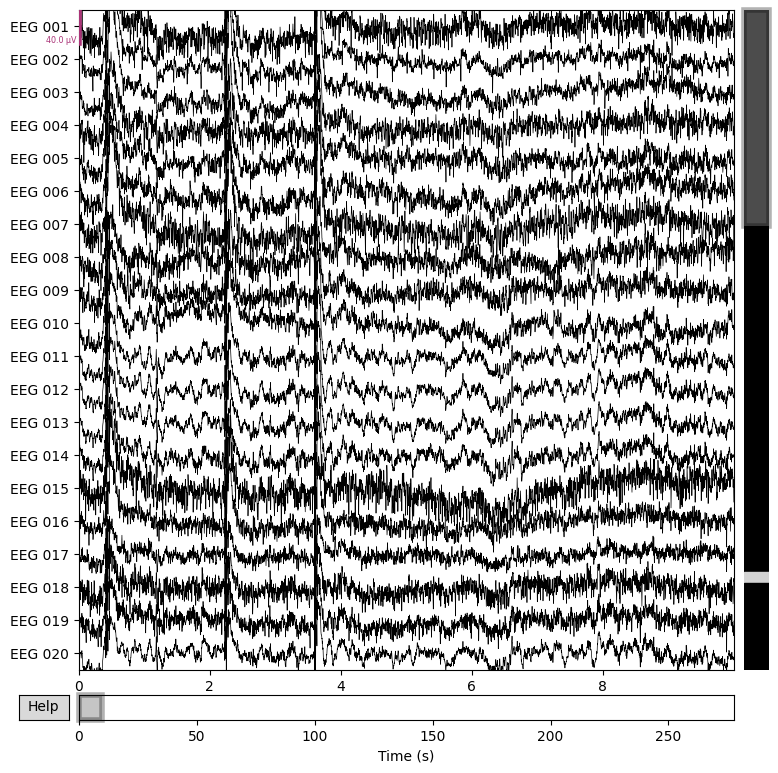

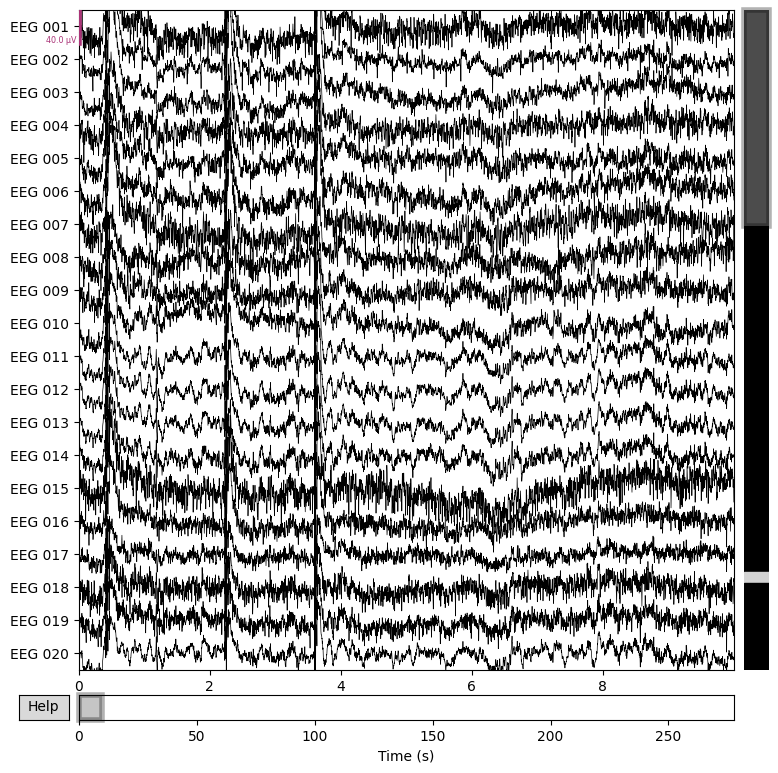

In [24]:
raw.copy().pick(['eeg', 'eog']).plot()

In [25]:
raw_eeg = raw.copy().pick('eeg').filter(0.5, 40)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 3965 samples (6.602 s)



In [26]:
from mne.preprocessing import ICA
ica = ICA(n_components=20, random_state=42)

In [27]:
ica.fit(raw_eeg)

Fitting ICA to data using 59 channels (please be patient, this may take a while)
Selecting by number: 20 components
Fitting ICA took 30.4s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,42 iterations on raw data (166800 samples)
ICA components,20
Available PCA components,59
Channel types,eeg
ICA components marked for exclusion,—


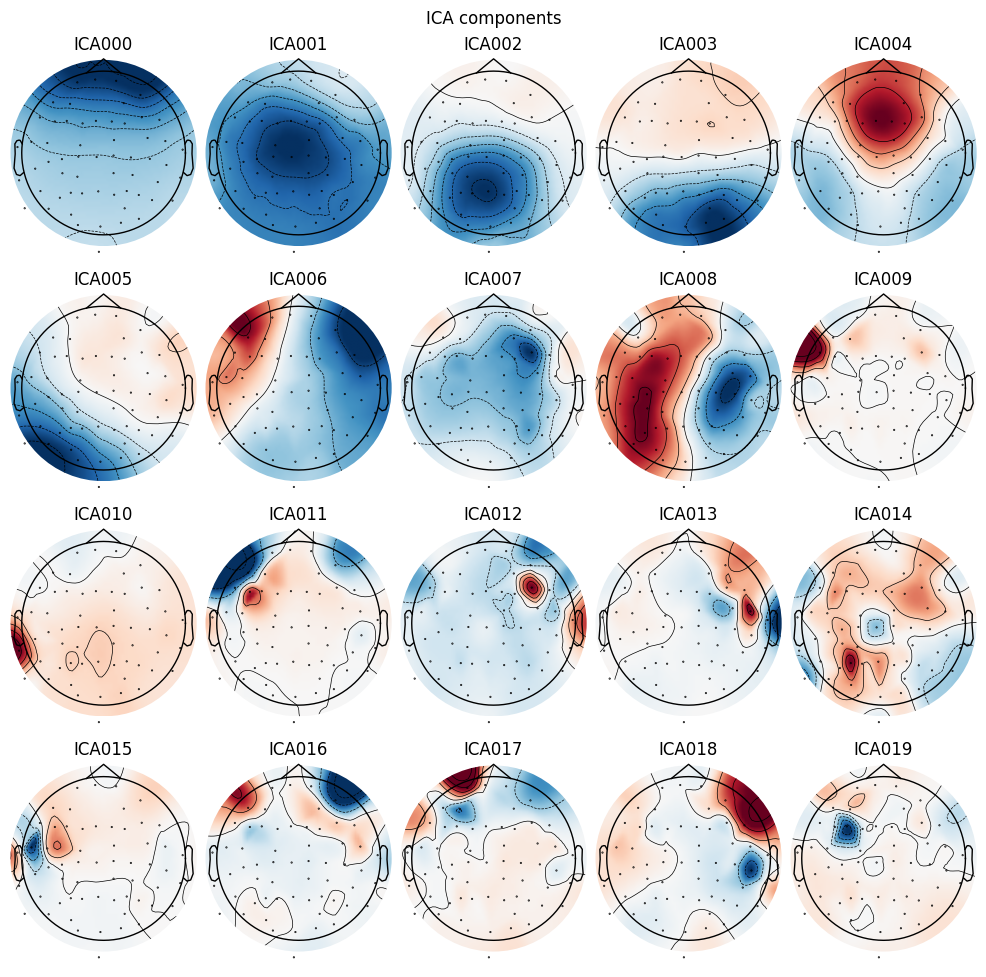

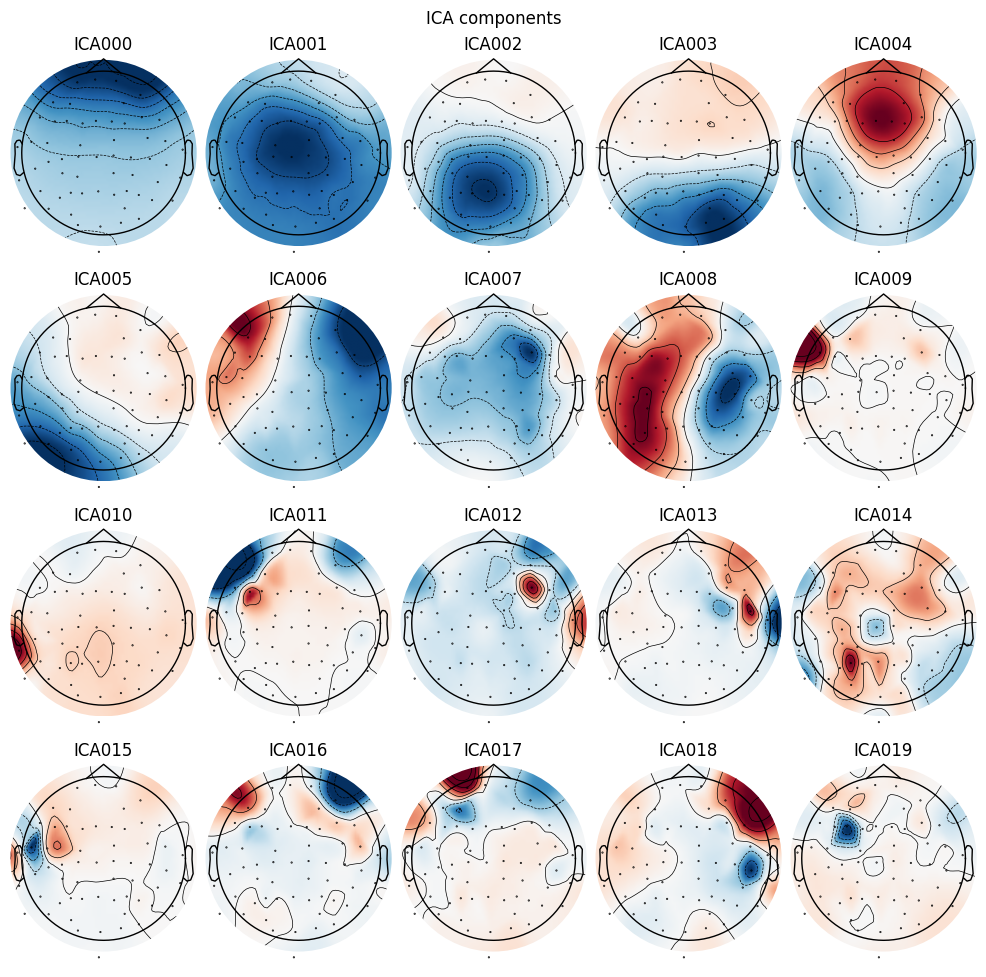

In [28]:
ica.plot_components()

In [29]:
ica.find_bads_eog(raw)

Using EOG channel: EOG 061
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 6007 samples (10.001 s)

... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz

([np.int64(0)],
 array([ 0.97909878, -0.09330794, -0.04346043, -0.04678376, -0.06823533,
        -0.01800807,  0.03287384,  0.00667989, -0.0131241 ,  0.01023453,
         0.04050951, -0.0362341 ,  0.01238478,  0.01250861, -0.02259128,
        -0.05999616,  0.07099918,  0.05592741, -0.02945683,  0.03282801]))

In [30]:
ica.exclude = [0.97909878, -0.09330794, -0.04346043, -0.04678376, -0.06823533,
        -0.01800807,  0.03287384,  0.00667989, -0.0131241 ,  0.01023453,
         0.04050951, -0.0362341 ,  0.01238478,  0.01250861, -0.02259128,
        -0.05999616,  0.07099918,  0.05592741, -0.02945683,  0.03282801]
raw_clean = raw_eeg.copy()
ica.apply(raw_clean)

Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 0 ICA components
    Projecting back using 59 PCA components


<Raw | sample_audvis_raw.fif, 60 x 166800 (277.7 s), ~79.3 MiB, data loaded>

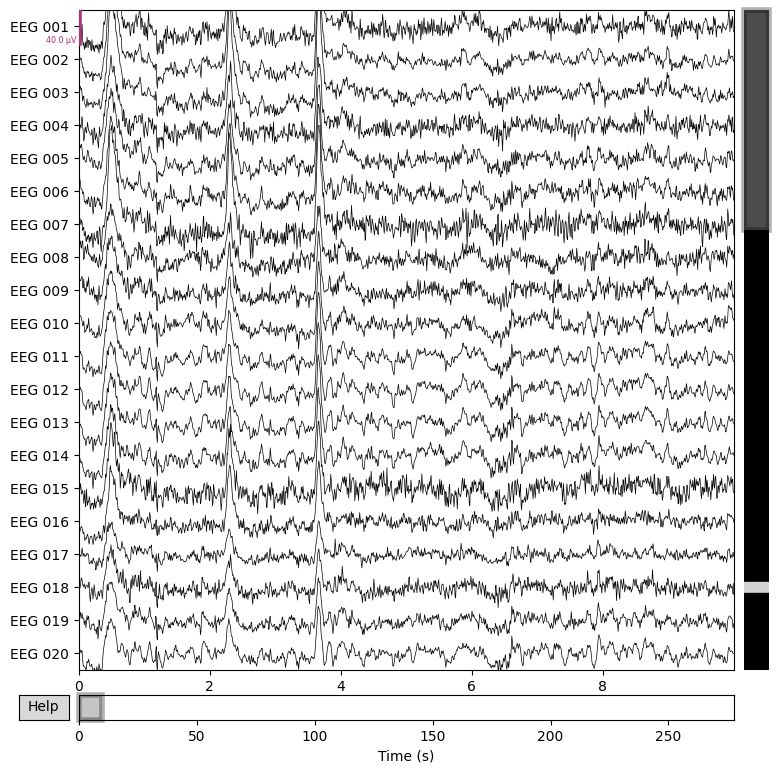

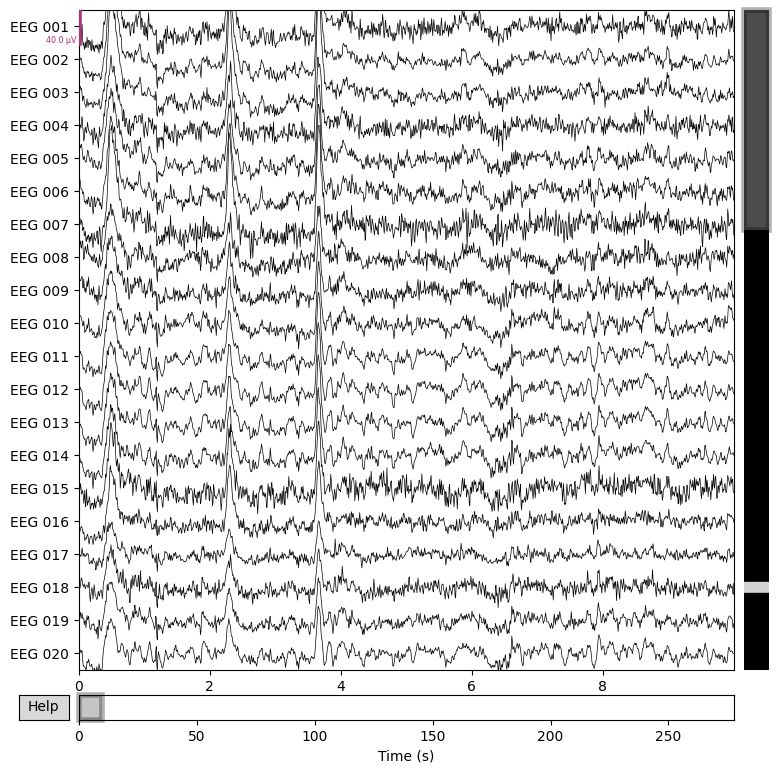

In [31]:
raw_clean.plot()

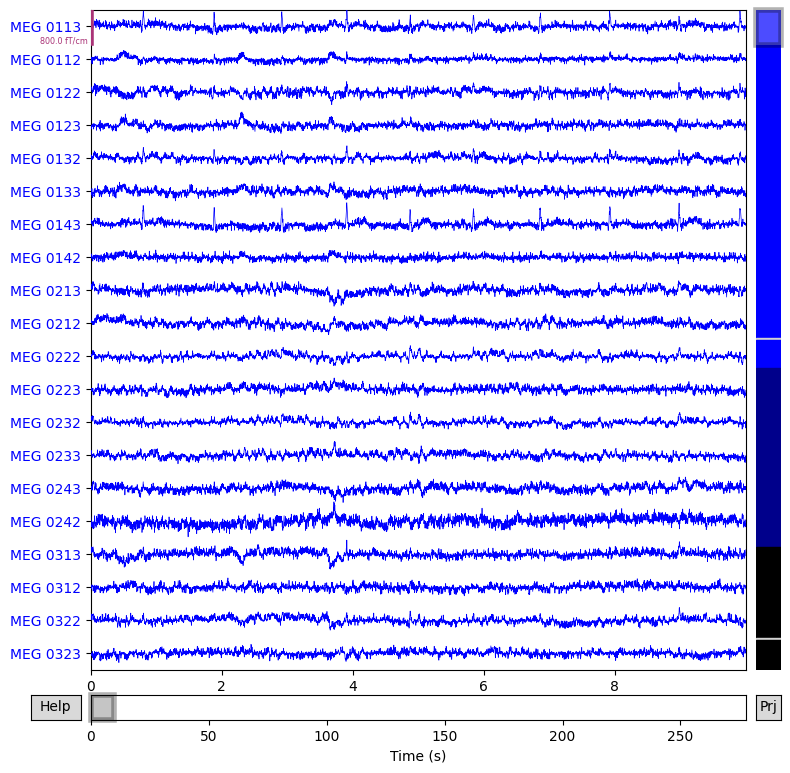

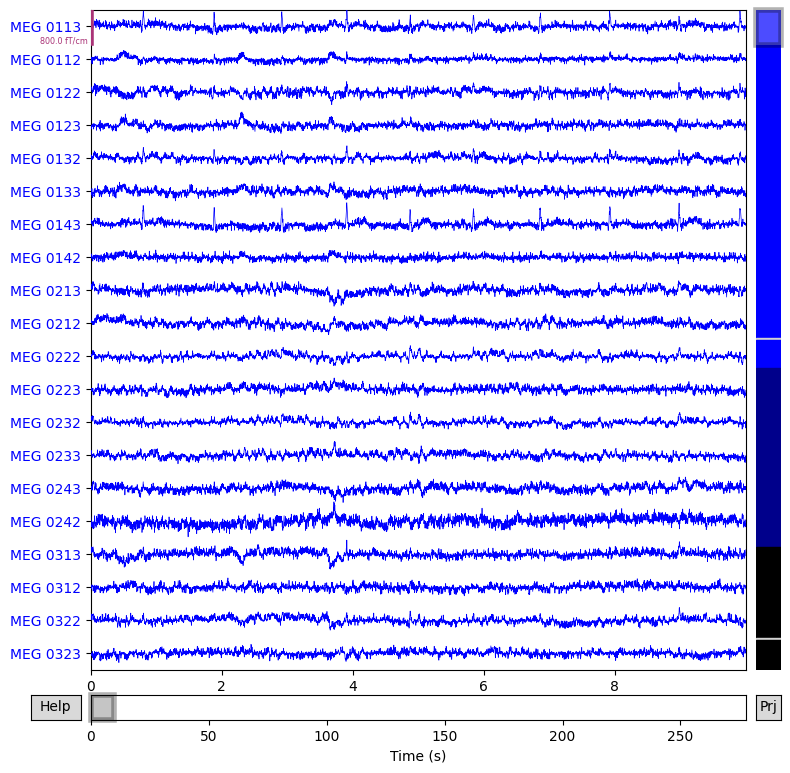

In [32]:
raw.plot()

In [33]:
psd = raw_clean.compute_psd(fmin=0.5, fmax=40)

Effective window size : 3.410 (s)


In [34]:
data = psd.get_data()
freqs = psd.freqs

In [35]:
alpha_idx = np.where((freqs >= 8) & (freqs <= 13))[0]
alpha_power = np.mean(data[:, alpha_idx], axis=1)
beta_idx = np.where((freqs >= 13) & (freqs <= 30))[0]
beta_power = np.mean(data[:, beta_idx], axis=1)
theta_idx = np.where((freqs >= 4) & (freqs <= 7))[0]
theta_power = np.mean(data[:, theta_idx], axis=1)

X = np.vstack([alpha_power, beta_power, theta_power]).T

In [36]:
import random

labels = [random.randint(0, 1) for _ in range(59)]

In [37]:
len(labels) == X.shape[0]

True

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
model = LogisticRegression()
model.fit(X, labels)
preds = model.predict(X)
accuracy = accuracy_score(labels, preds)
print("Accuracy: ", accuracy)

Accuracy:  0.576271186440678


In [39]:
events = mne.find_events(raw)

Finding events on: STI 014
320 events found on stim channel STI 014
Event IDs: [ 1  2  3  4  5 32]


In [40]:
print(events[:10])

[[27977     0     2]
 [28345     0     3]
 [28771     0     1]
 [29219     0     4]
 [29652     0     2]
 [30025     0     3]
 [30450     0     1]
 [30839     0     4]
 [31240     0     2]
 [31665     0     3]]


In [41]:
total_events = len(events)
print(total_events)

320


In [42]:
total_samples = raw.n_times
print(total_samples)

166800


In [43]:
np.unique(events[:, 2])

array([ 1,  2,  3,  4,  5, 32])

In [44]:
event_id = {
    "class_1": 1,
    "class_2": 2,
    "class_3": 3,
    "class_4": 4,
    "class_5": 5,
    "class_6": 32
}

In [45]:
epochs = mne.Epochs(
    raw_clean,
    events,
    event_id=event_id,
    tmin=0.0,
    tmax=1.0,
    baseline=None,
    preload=True
)

Not setting metadata
320 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 320 events and 602 original time points ...
0 bad epochs dropped


In [46]:
X = epochs.get_data()
y = epochs.events[:, 2]

In [47]:
data = epochs.get_data()

In [48]:
epoch_data = data[0]

In [49]:
from mne.time_frequency import psd_array_welch

# psd, freqs = psd_array_welch(
#     epoch_data,
#     sfreq=raw.info['sfreq'],
#     fmin=0.5,
#     fmax=40
# )

In [50]:
# alpha_idx = np.where((freqs >= 8) & (freqs <= 13))
# alpha_power = np.mean(psd[:, alpha_idx], axis=(1,2))
# beta_idx = np.where((freqs >= 13) & (freqs <= 30))
# beta_power = np.mean(psd[:, beta_idx], axis=(1,2))
# theta_idx = np.where((freqs >= 4) & (freqs <= 7))
# theta_power = np.mean(psd[:, theta_idx], axis=(1,2))

In [51]:
features = []

for i in range(data.shape[0]):
  epoch_data = data[i]

  psd, freqs = psd_array_welch(
      epoch_data,
      sfreq=raw.info['sfreq'],
      fmin=0.5,
      fmax=40
  )

  alpha_idx = np.where((freqs >= 8) & (freqs <= 13))
  beta_idx = np.where((freqs >= 13) & (freqs <= 30))
  theta_idx = np.where((freqs >= 4) & (freqs <= 7))


  alpha_power = np.mean(psd[:, alpha_idx[0]])
  beta_power = np.mean(psd[:, beta_idx[0]])
  theta_power = np.mean(psd[:, theta_idx[0]])


  features.append([theta_power, alpha_power, beta_power])

X = np.array(features)


Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective window size : 0.426 (s)
Effective wind

In [52]:
print(X.shape)
print(X[0])
print(type(X[0][0]))

(320, 3)
[2.67934332e-12 2.46746777e-12 4.32565114e-13]
<class 'numpy.float64'>


In [53]:
#labels
# y = epochs.events[:, 2]
y_binary = (y == 1).astype(int)

In [54]:
model = LogisticRegression()
model.fit(X, y_binary)
preds = model.predict(X)
accuracy = accuracy_score(y_binary, preds)
print("Accuracy: ", accuracy)

Accuracy:  0.775


In [55]:
np.unique(y)

array([ 1,  2,  3,  4,  5, 32])

In [56]:
from mne.decoding import CSP

csp = CSP(n_components=4)

X = epochs.get_data()
y = y_binary

X_csp = csp.fit_transform(X, y)

# model = LogisticRegression()
# model.fit(X_csp, y)
# preds = model.predict(X_csp)
# accuracy = accuracy_score(y, preds)
# print("Accuracy:", accuracy)

Computing rank from data with rank=None
    Using tolerance 0.00042 (2.2e-16 eps * 60 dim * 3.2e+10  max singular value)
    Estimated rank (data): 60
    data: rank 60 computed from 60 data channels with 0 projectors
Reducing data rank from 60 -> 60
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.


In [57]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X_csp, y, test_size=0.2, random_state=42
)

model = LogisticRegression(class_weight='balanced')
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model.fit(X_train_scaled, y_train)
preds = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, preds)
print("Accuracy:", accuracy)

Accuracy: 0.75


In [58]:
from sklearn.metrics import confusion_matrix

# cm = confusion_matrix(y_test, preds)
# print(cm)

In [59]:
from sklearn.metrics import classification_report

print(classification_report(y_test, preds))

              precision    recall  f1-score   support

           0       0.93      0.76      0.84        55
           1       0.32      0.67      0.43         9

    accuracy                           0.75        64
   macro avg       0.62      0.72      0.63        64
weighted avg       0.85      0.75      0.78        64



In [60]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    LogisticRegression(class_weight='balanced'),
    X_csp,
    y,
    cv=5
)

print("CV Accuracy:", scores)
print("Mean Accuracy:", scores.mean())

CV Accuracy: [0.703125 0.734375 0.703125 0.578125 0.75    ]
Mean Accuracy: 0.69375


In [61]:
# from sklearn.ensemble import RandomForestClassifier

# model = RandomForestClassifier(n_estimators=100, class_weight='balanced')
# model.fit(X_train, y_train)
# preds = model.predict(X_test)
# accuracy = accuracy_score(y_test, preds)
# print("Accuracy:", accuracy)
# print(classification_report(y_test, preds))